<a href="https://colab.research.google.com/github/2303a51210/quantum_computing_project/blob/main/45_problem__PHOTONIC_QUANTUM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [15]:
!pip install strawberryfields torch scipy pandas matplotlib seaborn scikit-learn -q

Device: cpu
Photonic Simulator: Strawberry Fields
Photonic Modes: 1
Qubits: 0

Dataset: Gaussian Mixture
Samples: 12000
Mean: -0.0091
Standard Deviation: 1.8353

Dataset: Beta(2,5)
Samples: 12000
Mean: 0.2871
Standard Deviation: 0.1607


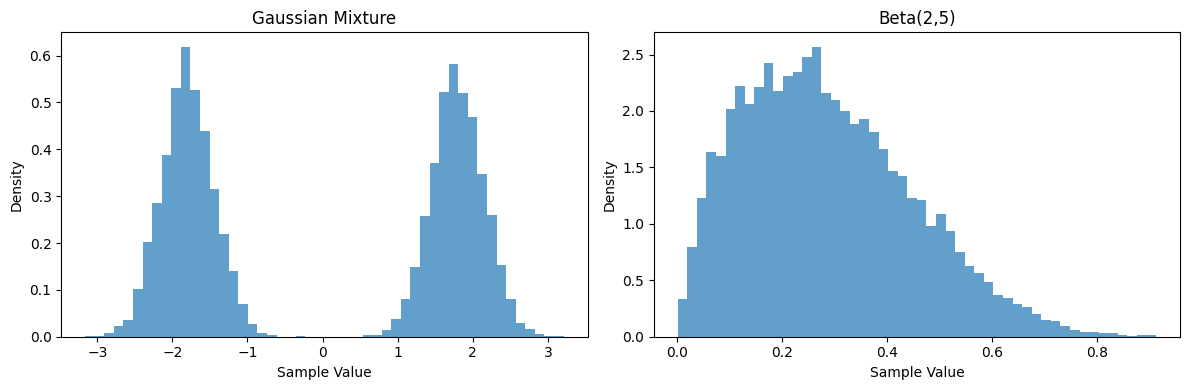


TRAINING: Gaussian Mixture
Epoch: 10 | D Loss: -6e-05 | G Loss: 0.00162
Epoch: 20 | D Loss: -0.00012 | G Loss: 0.00159
Epoch: 30 | D Loss: -0.00012 | G Loss: 0.0016
Epoch: 40 | D Loss: -0.00022 | G Loss: 0.00159
Epoch: 50 | D Loss: -0.00015 | G Loss: 0.00163
Epoch: 60 | D Loss: -0.00035 | G Loss: 0.00163

========== PERFORMANCE RESULTS ==========
Wasserstein-1 Distance: 0.834771
MMD: 0.188773
Mode Coverage: 100.0 %
Mean Photon Number: 0.060569
Estimated Truncation Probability: 1e-08

========== QUANTUM RESOURCE COST ==========
Qubits: 0
Photonic Modes: 1
Optical Gate Depth: 3
Total Sequential Operations: 4
Fock Cutoff: 10
Training Measurement Shots per Circuit: 128
Generation Measurement Shots: 2000
Total Measurement Shots: 40400
Circuit Evaluations: 301
Training Time: 563.21 seconds
Inference Time: 1.9885 seconds


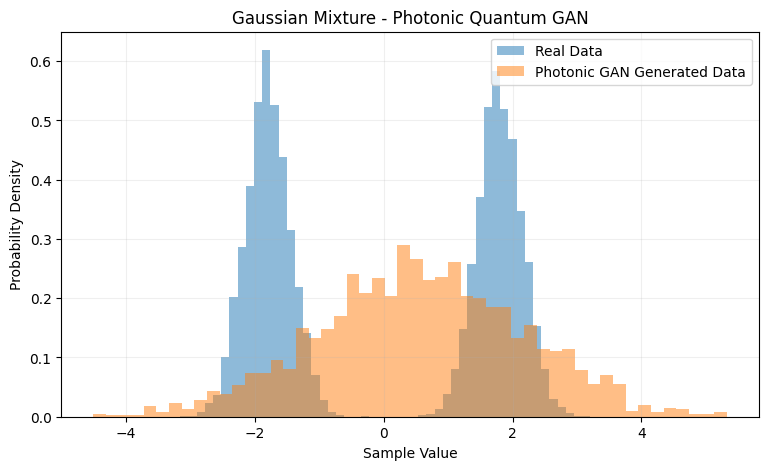


TRAINING: Beta(2,5)
Epoch: 10 | D Loss: -8e-05 | G Loss: -0.01006
Epoch: 20 | D Loss: -0.00019 | G Loss: -0.00976
Epoch: 30 | D Loss: -0.00041 | G Loss: -0.00946
Epoch: 40 | D Loss: -0.00033 | G Loss: -0.00936
Epoch: 50 | D Loss: -0.00053 | G Loss: -0.00923
Epoch: 60 | D Loss: -0.00061 | G Loss: -0.00894

========== PERFORMANCE RESULTS ==========
Wasserstein-1 Distance: 0.052188
MMD: 0.001989
Mode Coverage: 100.0 %
Mean Photon Number: 0.059591
Estimated Truncation Probability: 1e-08

========== QUANTUM RESOURCE COST ==========
Qubits: 0
Photonic Modes: 1
Optical Gate Depth: 3
Total Sequential Operations: 4
Fock Cutoff: 10
Training Measurement Shots per Circuit: 128
Generation Measurement Shots: 2000
Total Measurement Shots: 40400
Circuit Evaluations: 301
Training Time: 541.16 seconds
Inference Time: 1.6846 seconds


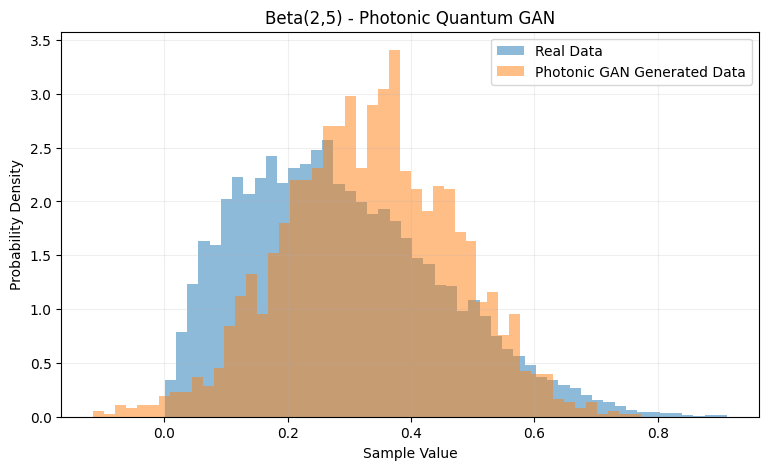


========== FINAL PQGAN COMPARISON ==========
         Dataset  Wasserstein-1      MMD  Mode Coverage  Mean Photon Number  Truncation Probability  Circuit Depth  Photonic Modes  Qubits  Training Shots  Total Shots  Circuit Evaluations  Training Time  Inference Time
Gaussian Mixture       0.834771 0.188773            1.0            0.060569            5.100135e-09              3               1       0             128        40400                  301     563.208455        1.988490
       Beta(2,5)       0.052188 0.001989            1.0            0.059591            5.676785e-09              3               1       0             128        40400                  301     541.161036        1.684609

All datasets trained successfully.
Generated CSV files saved.
Final results saved as PQGAN_Final_Results.csv


In [16]:

# ============================================================
# PHOTONIC QUANTUM GAN (PQGAN)
# D25: One-Dimensional Gaussian Mixture
# D36: Beta(2,5) Continuous Distribution
# Strawberry Fields - Photonic Fock Simulator
# ============================================================

# 1. IMPORT LIBRARIES

import os
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# SciPy compatibility
import scipy.integrate

if not hasattr(scipy.integrate, "simps"):
    scipy.integrate.simps = scipy.integrate.simpson

import torch
import torch.nn as nn
import torch.optim as optim

import strawberryfields as sf
from strawberryfields import ops

from scipy.stats import wasserstein_distance
from scipy.signal import find_peaks
from scipy.spatial.distance import cdist

# ============================================================
# 2. SETTINGS
# ============================================================

SEED = 42
ITERATIONS = 60
BATCH_SIZE = 128
GENERATED_SAMPLES = 2000
CUTOFF = 10

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

np.random.seed(SEED)
random.seed(SEED)
torch.manual_seed(SEED)

print("Device:", DEVICE)
print("Photonic Simulator: Strawberry Fields")
print("Photonic Modes: 1")
print("Qubits: 0")

# ============================================================
# 3. FIND AND LOAD DATASETS
# ============================================================

dataset_files = {}

required_files = [
    "D25_gaussian_mixture.csv",
    "D36_beta_2_5.csv"
]

search_locations = [
    "/kaggle/input",
    "/content",
    "/mnt/data"
]

for folder in search_locations:

    if os.path.exists(folder):

        for root, dirs, files in os.walk(folder):

            for filename in required_files:

                if filename in files:
                    dataset_files[filename] = os.path.join(
                        root, filename
                    )

DATASETS = {
    "Gaussian Mixture": "D25_gaussian_mixture.csv",
    "Beta(2,5)": "D36_beta_2_5.csv"
}

data = {}

for name, filename in DATASETS.items():

    if filename not in dataset_files:
        raise FileNotFoundError(
            "Dataset not found: " + filename +
            ". Upload both CSV files to Kaggle."
        )

    df = pd.read_csv(dataset_files[filename])

    if "sample" not in df.columns:
        raise ValueError(
            filename + " must contain a 'sample' column."
        )

    samples = df["sample"].dropna().values.astype(
        np.float32
    )

    mean = samples.mean()
    std = samples.std()

    normalized = (samples - mean) / (std + 1e-8)

    data[name] = {
        "original": samples,
        "normalized": normalized,
        "mean": mean,
        "std": std
    }

    print("\nDataset:", name)
    print("Samples:", len(samples))
    print("Mean:", round(float(mean), 4))
    print("Standard Deviation:", round(float(std), 4))

# ============================================================
# 4. ORIGINAL DATASET VISUALIZATION
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, (name, dataset) in zip(axes, data.items()):

    ax.hist(
        dataset["original"],
        bins=50,
        density=True,
        alpha=0.7
    )

    ax.set_title(name)
    ax.set_xlabel("Sample Value")
    ax.set_ylabel("Density")

plt.tight_layout()
plt.show()

# ============================================================
# 5. PHOTONIC QUANTUM GENERATOR
# ============================================================

# ============================================================
# FIXED PHOTONIC QUANTUM GENERATOR
# Fock backend does not support MeasureX with shots.
# We calculate the homodyne quadrature probability distribution
# and sample continuous values from it.
# ============================================================

def quantum_generator(theta, n_samples, cutoff=CUTOFF):

    # Trainable photonic parameters
    kerr = 0.3 * np.tanh(theta[0])
    squeeze = 1.0 * np.tanh(theta[1])
    displacement = 1.5 * np.tanh(theta[2])

    scale = np.exp(0.5 * np.tanh(theta[3]))
    shift = 0.5 * np.tanh(theta[4])

    # Define quadrature grids BEFORE calculating probabilities
    x_grid = np.linspace(-6.0, 6.0, 1000)
    p_grid = np.linspace(-8.0, 8.0, 1000)

    # Create one-mode photonic circuit
    circuit = sf.Program(1)

    with circuit.context as q:

        # Squeezing gate
        ops.Sgate(squeeze) | q[0]

        # Displacement gate
        ops.Dgate(displacement) | q[0]

        # Kerr nonlinear gate
        ops.Kgate(kerr) | q[0]

    # Run Fock simulator WITHOUT MeasureX
    engine = sf.Engine(
        "fock",
        backend_options={"cutoff_dim": cutoff}
    )

    result = engine.run(circuit)

    # Extract simulated photonic quantum state
    state = result.state

    # Calculate continuous X-quadrature probability density
    probs = np.asarray(
        state.x_quad_values(0, x_grid, p_grid)
    ).flatten()

    # Remove numerical errors
    probs = np.nan_to_num(
        probs,
        nan=0.0,
        posinf=0.0,
        neginf=0.0
    )

    # Remove small negative numerical values
    probs = np.maximum(probs, 0.0)

    # Normalize probability distribution
    total = probs.sum()

    if total <= 0:
        raise ValueError(
            "Invalid photonic quadrature probability distribution"
        )

    probs = probs / total

    # Sample continuous homodyne quadrature values
    quantum_samples = np.random.choice(
        x_grid,
        size=n_samples,
        p=probs
    )

    # Trainable output transformation
    generated = quantum_samples * scale + shift

    return generated.astype(np.float32)



# ============================================================
# 6. CLASSICAL DISCRIMINATOR
# ============================================================

class Discriminator(nn.Module):

    def __init__(self):

        super().__init__()

        self.network = nn.Sequential(

            nn.Linear(1, 64),
            nn.LeakyReLU(0.2),

            nn.Linear(64, 64),
            nn.LeakyReLU(0.2),

            nn.Linear(64, 1)
        )

    def forward(self, x):

        return self.network(x)


# ============================================================
# 7. MMD EVALUATION
# ============================================================

def calculate_mmd(real, generated):

    real = np.asarray(real).reshape(-1, 1)

    generated = np.asarray(generated).reshape(-1, 1)

    # Gaussian RBF kernel
    def kernel(x, y):

        distances = cdist(
            x, y, metric="sqeuclidean"
        )

        return np.exp(-distances / 2.0)

    k_xx = kernel(real, real)

    k_yy = kernel(generated, generated)

    k_xy = kernel(real, generated)

    n = len(real)
    m = len(generated)

    # Unbiased MMD
    xx = (
        k_xx.sum() - np.trace(k_xx)
    ) / (n * (n - 1))

    yy = (
        k_yy.sum() - np.trace(k_yy)
    ) / (m * (m - 1))

    xy = k_xy.mean()

    return max(0.0, xx + yy - 2 * xy)


# ============================================================
# 8. MODE COVERAGE
# ============================================================

def calculate_mode_coverage(real, generated):

    real_hist, bins = np.histogram(
        real,
        bins=50,
        density=True
    )

    centers = (bins[:-1] + bins[1:]) / 2

    # Identify real distribution peaks
    peaks, _ = find_peaks(
        real_hist,
        prominence=max(
            0.05 * real_hist.max(), 1e-8
        )
    )

    if len(peaks) == 0:
        return None

    gen_hist, _ = np.histogram(
        generated,
        bins=bins,
        density=True
    )

    gen_centers = centers

    # Identify generated distribution peaks
    gen_peaks, _ = find_peaks(
        gen_hist,
        prominence=max(
            0.05 * gen_hist.max(), 1e-8
        )
    )

    real_modes = centers[peaks]

    generated_modes = gen_centers[gen_peaks]

    covered = 0

    # Check how many real modes are generated
    for mode in real_modes:

        if len(generated_modes) > 0:

            threshold = 2 * (bins[1] - bins[0])

            if np.min(
                np.abs(generated_modes - mode)
            ) <= threshold:

                covered += 1

    return covered / len(real_modes)


# ============================================================
# 9. PHOTON NUMBER AND TRUNCATION DIAGNOSTICS
# ============================================================

def photon_diagnostics(theta, cutoff):

    kerr = 0.3 * np.tanh(theta[0])

    squeeze = 1.0 * np.tanh(theta[1])

    displacement = 1.5 * np.tanh(theta[2])

    # Higher cutoff reference simulation
    diagnostic_cutoff = cutoff + 10

    circuit = sf.Program(1)

    with circuit.context as q:

        ops.Sgate(squeeze) | q[0]

        ops.Dgate(displacement) | q[0]

        ops.Kgate(kerr) | q[0]

    engine = sf.Engine(
        "fock",
        backend_options={
            "cutoff_dim": diagnostic_cutoff
        }
    )

    result = engine.run(circuit)

    probabilities = np.asarray(
        result.state.all_fock_probs()
    ).reshape(-1)

    # Mean photon number
    photon_numbers = np.arange(len(probabilities))

    mean_photons = np.sum(
        photon_numbers * probabilities
    )

    # Estimated probability beyond original cutoff
    truncation_error = np.sum(
        probabilities[cutoff:]
    )

    return mean_photons, truncation_error


# ============================================================
# 10. TRAIN PHOTONIC QUANTUM GAN
# ============================================================

def train_pqgan(name, dataset):

    print("\n====================================")
    print("TRAINING:", name)
    print("====================================")

    real_data = dataset["normalized"]

    real_tensor = torch.tensor(
        real_data,
        dtype=torch.float32,
        device=DEVICE
    ).reshape(-1, 1)

    # Initialize photonic parameters
    theta = np.array(
        [0.1, 0.2, 0.1, 0.1, 0.0],
        dtype=np.float64
    )

    discriminator = Discriminator().to(DEVICE)

    optimizer_D = optim.Adam(
        discriminator.parameters(),
        lr=0.0005
    )

    generator_lr = 0.03

    critic_steps = 3

    circuit_evaluations = 0

    total_measurement_shots = 0

    training_start = time.time()

    # ========================================================
    # 11. ADVERSARIAL TRAINING
    # ========================================================

    for epoch in range(ITERATIONS):

        # Train discriminator
        for _ in range(critic_steps):

            indices = torch.randint(
                0,
                len(real_tensor),
                (BATCH_SIZE,)
            )

            real_batch = real_tensor[indices]

            # Generate fake photonic samples
            fake_np = quantum_generator(
                theta,
                BATCH_SIZE
            )

            circuit_evaluations += 1
            total_measurement_shots += BATCH_SIZE

            fake_batch = torch.tensor(
                fake_np,
                dtype=torch.float32,
                device=DEVICE
            ).reshape(-1, 1)

            optimizer_D.zero_grad()

            real_score = discriminator(
                real_batch
            ).mean()

            fake_score = discriminator(
                fake_batch.detach()
            ).mean()

            # Wasserstein discriminator loss
            loss_D = fake_score - real_score

            loss_D.backward()

            optimizer_D.step()

            # WGAN weight clipping
            for parameter in discriminator.parameters():

                parameter.data.clamp_(-0.01, 0.01)

        # ====================================================
        # 12. SPSA GENERATOR OPTIMIZATION
        # ====================================================

        epsilon = 0.05

        delta = np.random.choice(
            [-1.0, 1.0],
            size=len(theta)
        )

        theta_plus = theta + epsilon * delta

        theta_minus = theta - epsilon * delta

        # Positive parameter evaluation
        fake_plus = quantum_generator(
            theta_plus,
            BATCH_SIZE
        )

        circuit_evaluations += 1
        total_measurement_shots += BATCH_SIZE

        # Negative parameter evaluation
        fake_minus = quantum_generator(
            theta_minus,
            BATCH_SIZE
        )

        circuit_evaluations += 1
        total_measurement_shots += BATCH_SIZE

        with torch.no_grad():

            plus_tensor = torch.tensor(
                fake_plus,
                dtype=torch.float32,
                device=DEVICE
            ).reshape(-1, 1)

            minus_tensor = torch.tensor(
                fake_minus,
                dtype=torch.float32,
                device=DEVICE
            ).reshape(-1, 1)

            loss_plus = -discriminator(
                plus_tensor
            ).mean().item()

            loss_minus = -discriminator(
                minus_tensor
            ).mean().item()

        # SPSA gradient
        gradient = (
            (loss_plus - loss_minus) /
            (2 * epsilon)
        ) * delta

        # Update quantum parameters
        theta -= generator_lr * gradient

        # Training progress
        if (epoch + 1) % 10 == 0:

            print(
                "Epoch:", epoch + 1,
                "| D Loss:", round(loss_D.item(), 5),
                "| G Loss:", round(
                    (loss_plus + loss_minus) / 2, 5
                )
            )

    training_time = time.time() - training_start

    # ========================================================
    # 13. GENERATE NEW SAMPLES AND INFERENCE TIME
    # ========================================================

    inference_start = time.time()

    generated_normalized = quantum_generator(
        theta,
        GENERATED_SAMPLES
    )

    inference_time = time.time() - inference_start

    circuit_evaluations += 1

    total_measurement_shots += GENERATED_SAMPLES

    generated = (
        generated_normalized * dataset["std"]
        + dataset["mean"]
    )

    # ========================================================
    # 14. PERFORMANCE EVALUATION
    # ========================================================

    real = dataset["original"]

    # Wasserstein-1 distance
    w1 = wasserstein_distance(
        real,
        generated
    )

    # Maximum Mean Discrepancy
    mmd = calculate_mmd(
        real[:2000],
        generated
    )

    # Mode coverage
    mode_coverage = calculate_mode_coverage(
        real,
        generated
    )

    # Photon number and truncation
    mean_photons, truncation_error = photon_diagnostics(
        theta,
        CUTOFF
    )

    # ========================================================
    # 15. FINAL PERFORMANCE REPORT
    # ========================================================

    print("\n========== PERFORMANCE RESULTS ==========")

    print(
        "Wasserstein-1 Distance:",
        round(w1, 6)
    )

    print(
        "MMD:",
        round(mmd, 6)
    )

    if mode_coverage is not None:

        print(
            "Mode Coverage:",
            round(mode_coverage * 100, 2), "%"
        )

    else:

        print("Mode Coverage: Not Available")

    print(
        "Mean Photon Number:",
        round(float(mean_photons), 6)
    )

    print(
        "Estimated Truncation Probability:",
        round(float(truncation_error), 8)
    )

    # ========================================================
    # 16. QUANTUM RESOURCE COST
    # ========================================================

    print("\n========== QUANTUM RESOURCE COST ==========")

    print("Qubits: 0")

    print("Photonic Modes: 1")

    print("Optical Gate Depth: 3")

    print("Total Sequential Operations: 4")

    print("Fock Cutoff:", CUTOFF)

    print("Training Measurement Shots per Circuit:", BATCH_SIZE)

    print("Generation Measurement Shots:", GENERATED_SAMPLES)

    print("Total Measurement Shots:", total_measurement_shots)

    print("Circuit Evaluations:", circuit_evaluations)

    print(
        "Training Time:",
        round(training_time, 2), "seconds"
    )

    print(
        "Inference Time:",
        round(inference_time, 4), "seconds"
    )

    # ========================================================
    # 17. REAL VS GENERATED GRAPH
    # ========================================================

    plt.figure(figsize=(9, 5))

    plt.hist(
        real,
        bins=50,
        density=True,
        alpha=0.5,
        label="Real Data"
    )

    plt.hist(
        generated,
        bins=50,
        density=True,
        alpha=0.5,
        label="Photonic GAN Generated Data"
    )

    plt.title(name + " - Photonic Quantum GAN")

    plt.xlabel("Sample Value")

    plt.ylabel("Probability Density")

    plt.legend()

    plt.grid(alpha=0.2)

    plt.show()

    # Return all evaluation results
    return {
        "Dataset": name,
        "Wasserstein-1": w1,
        "MMD": mmd,
        "Mode Coverage": mode_coverage,
        "Mean Photon Number": mean_photons,
        "Truncation Probability": truncation_error,
        "Circuit Depth": 3,
        "Photonic Modes": 1,
        "Qubits": 0,
        "Training Shots": BATCH_SIZE,
        "Total Shots": total_measurement_shots,
        "Circuit Evaluations": circuit_evaluations,
        "Training Time": training_time,
        "Inference Time": inference_time,
        "Generated Samples": generated,
        "Parameters": theta
    }


# ============================================================
# 18. TRAIN BOTH DATASETS
# ============================================================

results = []

for name, dataset in data.items():

    result = train_pqgan(name, dataset)

    results.append(result)


# ============================================================
# 19. FINAL COMPARISON TABLE
# ============================================================

comparison = pd.DataFrame([

    {
        "Dataset": r["Dataset"],
        "Wasserstein-1": r["Wasserstein-1"],
        "MMD": r["MMD"],
        "Mode Coverage": r["Mode Coverage"],
        "Mean Photon Number": r["Mean Photon Number"],
        "Truncation Probability": r["Truncation Probability"],
        "Circuit Depth": r["Circuit Depth"],
        "Photonic Modes": r["Photonic Modes"],
        "Qubits": r["Qubits"],
        "Training Shots": r["Training Shots"],
        "Total Shots": r["Total Shots"],
        "Circuit Evaluations": r["Circuit Evaluations"],
        "Training Time": r["Training Time"],
        "Inference Time": r["Inference Time"]
    }

    for r in results

])

print("\n========== FINAL PQGAN COMPARISON ==========")

print(comparison.to_string(index=False))

# ============================================================
# 20. SAVE GENERATED DATA AND RESULTS
# ============================================================

for r in results:

    output_name = (
        r["Dataset"].replace(" ", "_")
        .replace("(", "").replace(")", "")
    )

    pd.DataFrame({
        "Generated_Samples": r["Generated Samples"]
    }).to_csv(
        output_name + "_generated.csv",
        index=False
    )

comparison.to_csv(
    "PQGAN_Final_Results.csv",
    index=False
)

print("\nAll datasets trained successfully.")
print("Generated CSV files saved.")
print("Final results saved as PQGAN_Final_Results.csv")

# ============================================================
# END OF PHOTONIC QUANTUM GAN
# ============================================================
